In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

In [3]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import string
import os
import json
from plotters import plot_differentiation_tree, plot_simulated_lineage_tree
from simulator import simulate_multitype_bd_with_diff, save_tree, filter_extant_lineages

## Single State

In [4]:
diff_T = nx.DiGraph()

diff_T.add_node("A", diff_time=None)

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:206: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


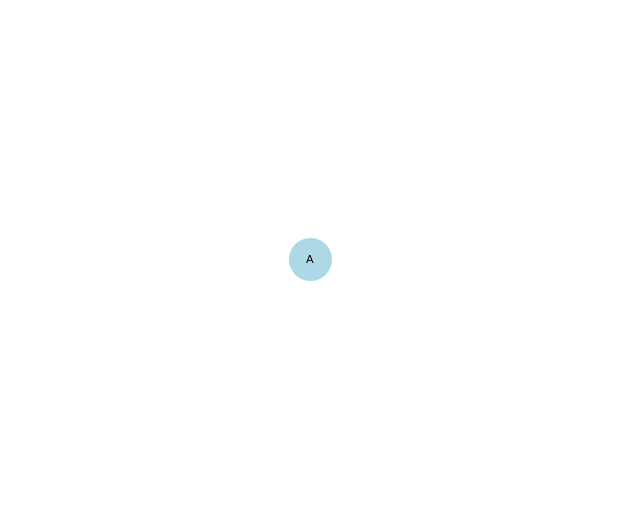

In [5]:
plot_differentiation_tree(diff_T)

KeyboardInterrupt: 

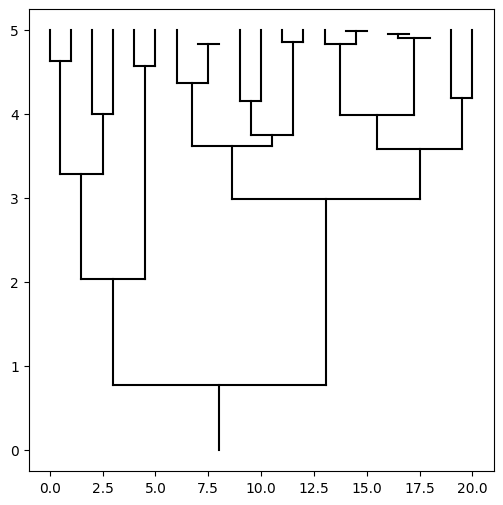

In [6]:
rooot = "../data/simulation/single"
os.makedirs(rooot, exist_ok=True)

param_id = 0

lams = [round(x * 0.1, 1) for x in range(1, 21)]

for lam in lams:

    root_dir = f"{rooot}/{param_id}"

    os.makedirs(root_dir, exist_ok=True)

    lam = {
        "A": lam,
    }

    mu = {
        "A": 0,
    }

    save_tree(diff_T, "A", f"{root_dir}/diff_T.json")

    params = {
        "birth_rates": lam,
        "death_rates": mu,
    }

    with open(f"{root_dir}/params.json", "w") as f:
        json.dump(params, f, indent=4)

    for seed in range(32):

        types = list(diff_T.nodes)

        Qs = pd.DataFrame(0.0, index=types, columns=types)

        save_dir = f"{root_dir}/{seed}"
        os.makedirs(save_dir, exist_ok=True)


        G, root = simulate_multitype_bd_with_diff(
            lam=lam,
            mu=mu,
            diff_T=diff_T,
            Qs=Qs,
            time_length=5,
            root_type="A",
            seed=seed,
        )

        # for u, v, data in G.edges(data=True):
        #     print((u, v), data)

        save_tree(G, root, f"{save_dir}/T.json")
        plot_simulated_lineage_tree(G, root)
        plt.savefig(f"{save_dir}/T.png")
        plt.close()

        G_extant = filter_extant_lineages(G, root)

        save_tree(G_extant, root, f"{save_dir}/T_extant.json")

        plot_simulated_lineage_tree(G_extant, root)
        plt.savefig(f"{save_dir}/T_extant.png")
        plt.close()

    param_id += 1


## Linear Differentiation

### differentiation map

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:206: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


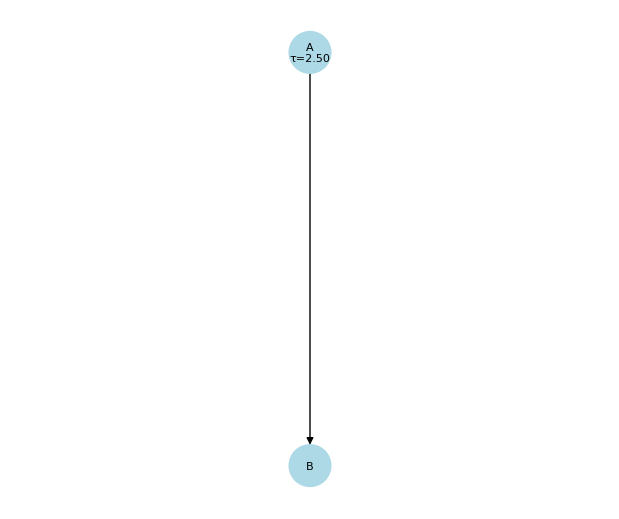

In [34]:
import string

diff_map_edges = [
    ("A", "B"),
]

diff_times = [2.5, None]

diff_T = nx.DiGraph()

for i, t in enumerate(diff_times):
    diff_T.add_node(string.ascii_uppercase[i], diff_time = t)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

plot_differentiation_tree(diff_T)

### simulate tree

In [8]:
rooot = "../data/simulation/linear"
os.makedirs(rooot, exist_ok=True)

param_id = 0

lams = [round(x * 0.2, 1) for x in range(1, 11)]
diff_times = [round(x * 1.0, 1) for x in range(1, 5)]

for diff_time in diff_times:
    
    diff_map_edges = [
        ("A", "B"),
    ]

    diff_times = [diff_time, None]

    diff_T = nx.DiGraph()

    for i, t in enumerate(diff_times):
        diff_T.add_node(string.ascii_uppercase[i], diff_time = t)

    for s, e in diff_map_edges:
        diff_T.add_edge(s, e)

    for lam1 in lams:
        for lam2 in lams:

            root_dir = f"{rooot}/{param_id}"

            os.makedirs(root_dir, exist_ok=True)

            lam = {
                "A": lam1,
                "B": lam2,
            }

            mu = {
                "A": 0,
                "B": 0,
            }

            save_tree(diff_T, "A", f"{root_dir}/diff_T.json")

            params = {
                "birth_rates": lam,
                "death_rates": mu,
            }

            with open(f"{root_dir}/params.json", "w") as f:
                json.dump(params, f, indent=4)

            # for seed in range(32):

            #     types = list(diff_T.nodes)

            #     Qs = pd.DataFrame(0.0, index=types, columns=types)

            #     save_dir = f"{root_dir}/{seed}"
            #     os.makedirs(save_dir, exist_ok=True)


            #     G, root = simulate_multitype_bd_with_diff(
            #         lam=lam,
            #         mu=mu,
            #         diff_T=diff_T,
            #         Qs=Qs,
            #         time_length=5,
            #         root_type="A",
            #         seed=seed,
            #     )

            #     # for u, v, data in G.edges(data=True):
            #     #     print((u, v), data)

            #     save_tree(G, root, f"{save_dir}/T.json")
            #     plot_simulated_lineage_tree(G, root)
            #     plt.savefig(f"{save_dir}/T.png")
            #     plt.close()

            #     G_extant = filter_extant_lineages(G, root)

            #     save_tree(G_extant, root, f"{save_dir}/T_extant.json")

            #     plot_simulated_lineage_tree(G_extant, root)
            #     plt.savefig(f"{save_dir}/T_extant.png")
            #     plt.close()

            param_id += 1


## Tree Differentiation

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:206: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


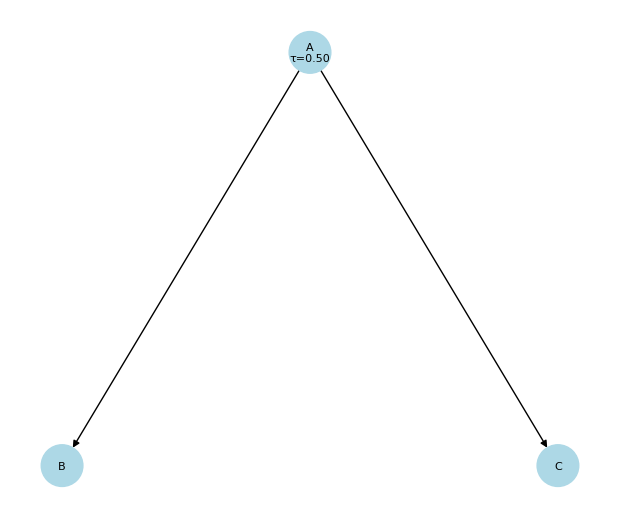

In [4]:
import string

diff_map_edges = [
    ("A", "B"),
    ("A", "C"),
]

diff_times = [0.5, None, None]

diff_T = nx.DiGraph()

for i, t in enumerate(diff_times):
    diff_T.add_node(string.ascii_uppercase[i], diff_time = t)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

plot_differentiation_tree(diff_T)

In [9]:
rooot = "../data/simulation/tree"
os.makedirs(rooot, exist_ok=True)

param_id = 0

lams = [round(x * 0.3, 1) for x in range(1, 7)]
diff_times = [1.0, 2.5, 4.0]
diff_bias = [0.3, 0.5, 0.7]

for diff_time in diff_times:
        
    diff_map_edges = [
        ("A", "B"),
        ("A", "C"),
    ]

    diff_times = [diff_time, None, None]

    diff_T = nx.DiGraph()

    for i, t in enumerate(diff_times):
        diff_T.add_node(string.ascii_uppercase[i], diff_time = t)

    for s, e in diff_map_edges:
        diff_T.add_edge(s, e)

    for diff_b in diff_bias:
        types = sorted(list(diff_T.nodes()))
        Qs = pd.DataFrame(0.0, index=types, columns=types)
        Qs.loc["A", "B"] = diff_b
        Qs.loc["A", "C"] = 1 - diff_b

        for lam1 in lams:
            for lam2 in lams:
                for lam3 in lams:

                    root_dir = f"{rooot}/{param_id}"

                    os.makedirs(root_dir, exist_ok=True)

                    lam = {
                        "A": lam1,
                        "B": lam2,
                        "C": lam3,
                    }

                    mu = {
                        "A": 0,
                        "B": 0,
                        "C": 0,
                    }

                    save_tree(diff_T, "A", f"{root_dir}/diff_T.json")

                    params = {
                        "birth_rates": lam,
                        "death_rates": mu,
                    }

                    with open(f"{root_dir}/params.json", "w") as f:
                        json.dump(params, f, indent=4)
                    
                    Qs.to_csv(f"{root_dir}/Q.csv")

                param_id += 1


### check likelihood

In [7]:
from simulator import load_tree

In [8]:
T, root = load_tree(f"{save_dir}/T_extant.json")

In [9]:
for u, v, data in T.edges(data=True):
    print(f"{u} -> {v} : {data}")

0 -> 1 : {'start_time': 0.0, 'end_time': 0.05080196914702305, 'length': 0.05080196914702305}
1 -> 2 : {'start_time': 0.05080196914702305, 'end_time': 0.06668742542484705, 'length': 0.015885456277824006}
1 -> 3 : {'start_time': 0.05080196914702305, 'end_time': 0.24294008378402152, 'length': 0.19213811463699848}
2 -> 4 : {'start_time': 0.06668742542484705, 'end_time': 0.43660822690361484, 'length': 0.36992080147876777}
2 -> 5 : {'start_time': 0.06668742542484705, 'end_time': 0.22395081705547248, 'length': 0.15726339163062542}
3 -> 10 : {'start_time': 0.24294008378402152, 'end_time': 0.32545054464449125, 'length': 0.08251046086046973}
3 -> 25 : {'start_time': 0.24294008378402152, 'end_time': 0.6613104311100458, 'length': 0.4183703473260243}
4 -> 30 : {'start_time': 0.43660822690361484, 'end_time': 0.8339652440794222, 'length': 0.39735701717580735}
4 -> 31 : {'start_time': 0.43660822690361484, 'end_time': 1.0, 'length': 0.5633917730963851}
5 -> 6 : {'start_time': 0.22395081705547248, 'end_

In [10]:
cell_lineage_T = nx.DiGraph()

for u, v, data in T.edges(data=True):
    cell_lineage_T.add_edge(u, v, weight=data['length'])

for n in T.nodes(data=True):
    if n[1]['event'] == 'sample':
        cell_lineage_T.nodes[n[0]]['type'] = n[1]['type']

In [11]:
from plotters import draw_ultrametric_tree

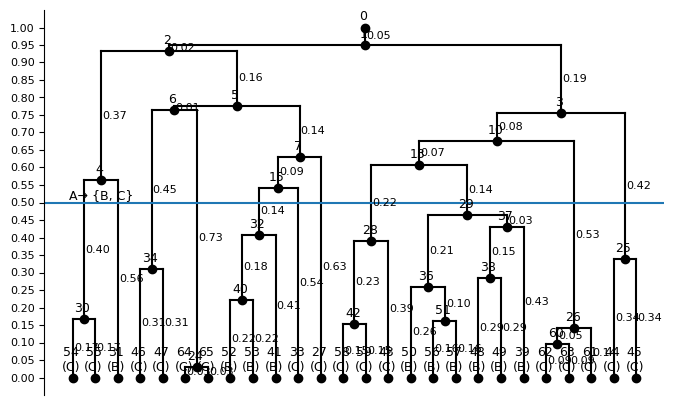

In [12]:
draw_ultrametric_tree(cell_lineage_T, root=root, diff_T=diff_T)

In [13]:
def add_node_times(cell_lineage_T, root=0):
    distances = nx.single_source_dijkstra_path_length(cell_lineage_T, root, weight='weight')
    for node, dist in distances.items():
        cell_lineage_T.nodes[node]['T'] = 1 - dist
    
    return cell_lineage_T

cell_lineage_T = add_node_times(cell_lineage_T)

In [14]:
from likelihood import calculate_likelihood_of_tree

In [15]:
birth_rates = {
    "A": 5.0,
    "B": 3.0,
    "C": 1.0,
}

death_rates = {
    "A": 0.3,
    "B": 0.2,
    "C": 0.2,
}

transition_probabilities = pd.DataFrame(0.0, index=types, columns=types)

# A -> B
transition_probabilities.loc["A", "B"] = 0.3
transition_probabilities.loc["A", "C"] = 0.7

calculate_likelihood_of_tree(
    birth_rates=birth_rates,
    death_rates=death_rates,
    sampling_rate=1.0,
    transition_probabilities=transition_probabilities,
    cell_lineage_T=cell_lineage_T,
    diff_T=diff_T
)

np.float64(2.516230818841366e-06)

In [16]:
birth_grid_B = np.linspace(0.0, 8.0, 100)
transition_grid = np.linspace(0.0, 1.0, 100)

In [17]:
L = np.zeros((
    len(birth_grid_B),
    len(transition_grid),
))

for iB, birth_rate_B in enumerate(birth_grid_B):
    for it, transition_rate_B in enumerate(transition_grid):

        birth_rates = {
            "A": 5.0,
            "B": birth_rate_B,
            "C": 1.0,
        }

        death_rates = {
            "A": 0.3,
            "B": 0.2,
            "C": 0.2,
        }

        transition_probabilities = pd.DataFrame(0.0, index=types, columns=types)

        # A -> B
        transition_probabilities.loc["A", "B"] = transition_rate_B
        transition_probabilities.loc["A", "C"] = 1 - transition_rate_B

        L[iB, it] = calculate_likelihood_of_tree(
            birth_rates=birth_rates,
            death_rates=death_rates,
            sampling_rate=1.0,
            transition_probabilities=transition_probabilities,
            cell_lineage_T=cell_lineage_T,
            diff_T=diff_T
        )


/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:39: RuntimeWarning: divide by zero encountered in scalar divide
  C = (U_child - 1) / (U_child - (death_rates[child] / birth_rates[child]))
/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:42: RuntimeWarning: divide by zero encountered in scalar divide
  (birth_rates[child] * (1 - (1 / C) *
/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:42: RuntimeWarning: invalid value encountered in scalar multiply
  (birth_rates[child] * (1 - (1 / C) *
/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:80: RuntimeWarning: divide by zero encountered in scalar divide
  C = (U_t - 1) / (U_t - (death_rates[state] / birth_rates[state]))


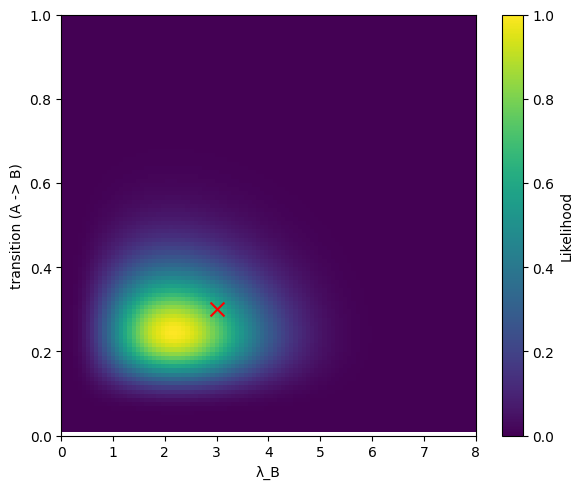

In [18]:
plt.figure(figsize=(6, 5))

plt.imshow(
    L,
    origin="lower",
    extent=[
        birth_grid_B.min(), birth_grid_B.max(),
        transition_grid.min(), transition_grid.max(),
    ],
    aspect="auto"
)

plt.scatter( 3.0, 0.3, marker="x", s=100, color='red')

plt.xlabel("λ_B")
plt.ylabel("transition (A -> B)")
plt.colorbar(label="Likelihood")
plt.tight_layout()
plt.show()

In [19]:
def unpack_params(theta):
    types = ['A', 'B', 'C']

    k = 0

    # Birth rates
    birth = {}
    for t in types:
        birth[t] = np.exp(theta[k])
        k += 1

    # Death rates
    death = {}
    for t in types:
        death[t] = np.exp(theta[k])
        k += 1

    # Transition matrix via softmax
    Q = pd.DataFrame(0.0, index=types, columns=types)

    transition_maps = [
        ('A', ['B', 'C']),
    ]

    for i, transition_to in transition_maps:
        logits = []
        js = []

        for j in transition_to:
            logits.append(theta[k])
            js.append(j)
            k += 1

        logits = np.array(logits)
        logits -= np.max(logits)  # numerical stability
        exp_logits = np.exp(logits)
        probs = exp_logits / exp_logits.sum()

        for idx, j in enumerate(js):
            Q.loc[i, j] = probs[idx]

    return birth, death, Q

In [20]:
def neg_log_likelihood(theta, cell_lineage_T, diff_T, sampling_rate=1.0):
    birth, death, Q = unpack_params(theta)

    p = calculate_likelihood_of_tree(
        birth_rates=birth,
        death_rates=death,
        sampling_rate=sampling_rate,
        transition_probabilities=Q,
        cell_lineage_T=cell_lineage_T,
        diff_T=diff_T
    )

    # if p <= 1e-300:
    #     return 1e6 

    return -np.log(p)


In [ ]:
def pack_initial():
    params = []
    types = ['A', 'B', 'C']
    transition_maps = [
        ('A', ['B', 'C']),
    ]

    # log birth
    for t in types:
        params.append(np.log(2))

    # log death
    for t in types:
        params.append(np.log(0.5))

    # transition logits (inverse softmax approx)
    for i, transition_to in transition_maps:
        for j in transition_to:
            params.append(np.log(0.5))

    return np.array(params)

In [ ]:
from scipy.optimize import minimize

theta0 = pack_initial()

result = minimize(
    neg_log_likelihood,
    theta0,
    args=(cell_lineage_T, diff_T, 1.0),
    method="L-BFGS-B"
)

unpack_params(result.x)

({'A': np.float64(5.594202830463034),
  'B': np.float64(1.8779799029689603),
  'C': np.float64(2.1462703960559386)},
 {'A': np.float64(1.9977399674533314e-06),
  'B': np.float64(3.0115786185628255e-07),
  'C': np.float64(2.670540007622855)},
      A         B         C
 A  0.0  0.125781  0.874219
 B  0.0  0.000000  0.000000
 C  0.0  0.000000  0.000000)

## More general graph

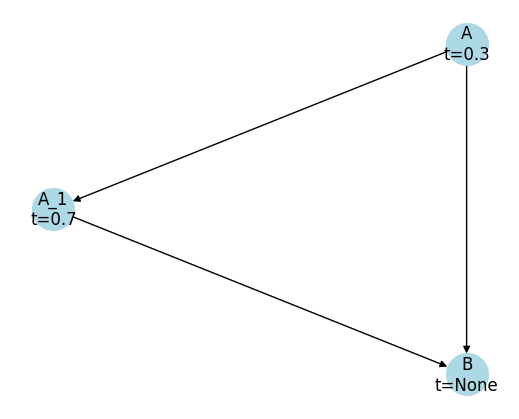

In [5]:
import string

diff_map_edges = [
    ("A", "A_1"),
    ("A", "B"),
    ("A_1", "B")
]

diff_T = nx.DiGraph()

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

diff_T.nodes['A']['diff_time'] = 0.3
diff_T.nodes['A_1']['diff_time'] = 0.7
diff_T.nodes['B']['diff_time'] = None

plot_differentiation_tree(diff_T)

In [6]:
from plotters import plot_simulated_lineage_tree
from simulator import simulate_multitype_bd_with_diff, save_tree, filter_extant_lineages

save_dir = "../data/simulation/test_diff_two_wave"

lam = {
    "A": 5.0,
    "A_1": 5.0,
    "B": 1.0,
}

mu = {
    "A": 0.3,
    "A_1": 0.3,
    "B": 0.1,
}

import pandas as pd

types = list(diff_T.nodes)

Qs = pd.DataFrame(0.0, index=types, columns=types)

# A -> B
Qs.loc["A", "B"] = 0.8
Qs.loc["A", "A_1"] = 0.2
Qs.loc["A_1", "B"] = 1.0


G, root = simulate_multitype_bd_with_diff(
    lam=lam,
    mu=mu,
    diff_T=diff_T,
    Qs=Qs,
    time_length=1.0,
    root_type="A",
    seed=3
)

for u, v, data in G.edges(data=True):
    print((u, v), data)

save_tree(G, root, f"{save_dir}/T.json")
plot_simulated_lineage_tree(G, root)

plt.savefig(f"{save_dir}/T.png")
plt.close()

G_extant = filter_extant_lineages(G, root)

save_tree(G_extant, root, f"{save_dir}/T_extant.json")

plot_simulated_lineage_tree(G_extant, root)

plt.savefig(f"{save_dir}/T_extant.png")
plt.close()


(0, 1) {'start_time': 0.0, 'end_time': 0.05127590627050346, 'length': 0.05127590627050346}
(1, 2) {'start_time': 0.05127590627050346, 'end_time': 0.2545767354651501, 'length': 0.20330082919464662}
(1, 3) {'start_time': 0.05127590627050346, 'end_time': 0.1386475256454493, 'length': 0.08737161937494584}
(2, 18) {'start_time': 0.2545767354651501, 'end_time': 0.3, 'length': 0.045423264534849905}
(2, 19) {'start_time': 0.2545767354651501, 'end_time': 0.3, 'length': 0.045423264534849905}
(3, 4) {'start_time': 0.1386475256454493, 'end_time': 0.3, 'length': 0.1613524743545507}
(3, 5) {'start_time': 0.1386475256454493, 'end_time': 0.13948120226460872, 'length': 0.0008336766191594236}
(4, 24) {'start_time': 0.3, 'end_time': 1.0, 'length': 0.7}
(5, 6) {'start_time': 0.13948120226460872, 'end_time': 0.2204043391593168, 'length': 0.08092313689470806}
(5, 7) {'start_time': 0.13948120226460872, 'end_time': 0.1520757903135584, 'length': 0.012594588048949668}
(6, 10) {'start_time': 0.2204043391593168, 

### check likelihood

In [7]:
from simulator import load_tree

In [8]:
T, root = load_tree(f"{save_dir}/T_extant.json")

In [9]:
cell_lineage_T = nx.DiGraph()

for u, v, data in T.edges(data=True):
    cell_lineage_T.add_edge(u, v, weight=data['length'])

for n in T.nodes(data=True):
    if n[1]['event'] == 'sample':
        cell_lineage_T.nodes[n[0]]['type'] = n[1]['type']

In [10]:
from plotters import draw_ultrametric_tree

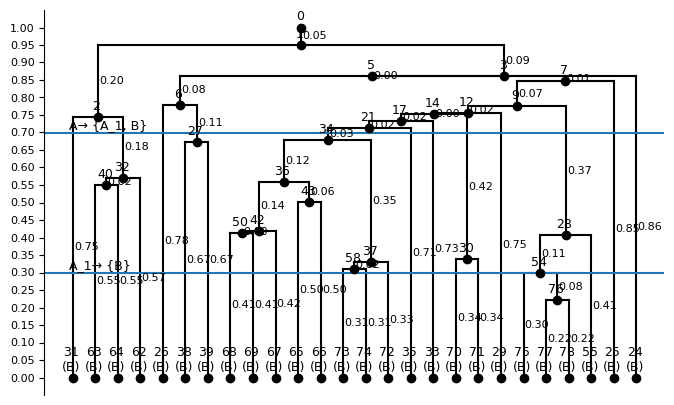

In [11]:
draw_ultrametric_tree(cell_lineage_T, root=root, diff_T=diff_T)

In [12]:
def add_node_times(cell_lineage_T, root=0):
    distances = nx.single_source_dijkstra_path_length(cell_lineage_T, root, weight='weight')
    for node, dist in distances.items():
        cell_lineage_T.nodes[node]['T'] = 1 - dist
    
    return cell_lineage_T

cell_lineage_T = add_node_times(cell_lineage_T)

In [13]:
from likelihood import calculate_likelihood_of_tree

In [14]:
birth_rates = {
    "A": 5.0,
    "A_1": 5.0,
    "B": 1.0,
}

death_rates = {
    "A": 0.3,
    "A_1": 0.3,
    "B": 0.1,
}

transition_probabilities = pd.DataFrame(0.0, index=types, columns=types)

transition_probabilities.loc["A", "B"] = 0.8
transition_probabilities.loc["A", "A_1"] = 0.2
transition_probabilities.loc["A_1", "B"] = 1.0

calculate_likelihood_of_tree(
    birth_rates=birth_rates,
    death_rates=death_rates,
    sampling_rate=1.0,
    transition_probabilities=transition_probabilities,
    cell_lineage_T=cell_lineage_T,
    diff_T=diff_T
)

np.float64(0.1516297649347023)

In [28]:
birth_grid_A = np.linspace(0.0, 10.0, 100)
transition_grid = np.linspace(0.0, 1.0, 100)

In [29]:
L = np.zeros((
    len(birth_grid_A),
    len(transition_grid),
))

EPS = 0.00001

for iA, birth_rate_A in enumerate(birth_grid_A):
    for it, transition_rate_B in enumerate(transition_grid):

        birth_rates = {
            "A": birth_rate_A + EPS,
            "A_1": birth_rate_A + EPS,
            "B": 1.0,
        }

        death_rates = {
            "A": 0.3,
            "A_1": 0.3,
            "B": 0.1,
        }

        transition_probabilities = pd.DataFrame(0.0, index=types, columns=types)

        transition_probabilities.loc["A", "B"] = transition_rate_B
        transition_probabilities.loc["A", "A_1"] = 1 - transition_rate_B
        transition_probabilities.loc["A_1", "B"] = 1.0

        L[iA, it] = calculate_likelihood_of_tree(
            birth_rates=birth_rates,
            death_rates=death_rates,
            sampling_rate=1.0,
            transition_probabilities=transition_probabilities,
            cell_lineage_T=cell_lineage_T,
            diff_T=diff_T
        )

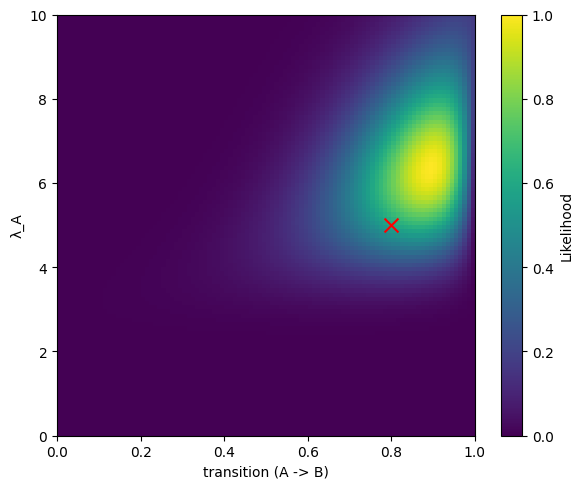

In [30]:
plt.figure(figsize=(6, 5))

plt.imshow(
    L,
    origin="lower",
    extent=[
        transition_grid.min(), transition_grid.max(),
        birth_grid_A.min(), birth_grid_A.max(),

    ],
    aspect="auto"
)

plt.scatter( 0.8, 5, marker="x", s=100, color='red')

plt.ylabel("λ_A")
plt.xlabel("transition (A -> B)")
plt.colorbar(label="Likelihood")
plt.tight_layout()
plt.show()